# 04 · E1: condition ablation (teacher forcing)

**Question.** Does the model use the tension and combat-score conditions? The review of the first submission noted that every reported metric is a teacher-forced cross-entropy, which could look the same even if the FiLM conditioning were disconnected.

**Method.** The test segments of Table 1 are evaluated again with the real conditions and with conditions that carry less or wrong information (`src/condition_ablation.py`): all zero, a constant median value, the segment's own values shuffled in time, and the conditions of another segment (both controls, or only one of them). Only the conditions change; tokens, model and code path are the same as in Table 1. If the model uses the conditions, the cross-entropy of the real tokens increases when they are replaced. The increase is measured per segment, with a bootstrap 95% confidence interval over segments.

**Data.** Slakh test split (151 tracks, the same 10-s crops as Table 1) for the three checkpoints; OST validation split (6 Skyrim + 6 Witcher 3 tracks, 4 crops each) for Slakh-FT and OST-FT.

**What it does not show.** A lower cross-entropy with the real conditions means the model has learned how the conditions relate to the audio. Whether changing the conditions at generation time changes the music as requested is experiment E2 (Phase 2).

**Kaggle settings:** GPU T4, Internet on. **Inputs:** `slakh-tensors-final`, `ost-tensors-sky-w3` and the three reported checkpoints (`secunda-slakh-60-epochs`, `secunda-finetuned-on-slakh`, `secunda-finetuned-on-ost-v2`).

In [1]:
# ── Repository bootstrap: make src/ importable on Kaggle and locally ──
# On Kaggle the repository is cloned into /kaggle/working (Internet must be
# enabled in the notebook settings). Locally, set SECUNDA_REPO_DIR to the
# repository root and nothing is cloned.
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/DanBracs7/Adaptive-Secunda-Synth.git"
REPO_BRANCH = "revision"  # switch to "main" after merging the revision
REPO_DIR = Path(os.environ.get("SECUNDA_REPO_DIR", "/kaggle/working/Adaptive-Secunda-Synth"))

if not (REPO_DIR / "src").exists():
    subprocess.run(
        ["git", "clone", "--depth", "1", "--branch", REPO_BRANCH, REPO_URL, str(REPO_DIR)],
        check=True,
    )

sys.path.insert(0, str(REPO_DIR / "src"))

commit = subprocess.run(
    ["git", "-C", str(REPO_DIR), "rev-parse", "--short", "HEAD"],
    capture_output=True,
    text=True,
).stdout.strip()

print("Repository:", REPO_DIR)
print("Commit:", commit or "unknown (not a git checkout)")

Cloning into '/kaggle/working/Adaptive-Secunda-Synth'...


Repository: /kaggle/working/Adaptive-Secunda-Synth
Commit: 5b824f2


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader

from audio_dataset import SecundaAudioDataset
from condition_ablation import ABLATIONS, ablate_conditions, bootstrap_mean_ci, per_segment_cross_entropy
from frame_codec import NUM_CODEBOOKS, CodebookSerializer
from paths import get_path, source_roots_for_split
from training_utils import load_checkpoint_model, multi_codebook_metrics, prepare_batch_for_model

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu")

RANDOM_SEED = 42            # same crops as notebook 01 / Table 1
ABLATION_SEED = 1234        # time shuffles; the same for every checkpoint
FRAME_RATE = 75
SEGMENT_SECONDS = 10.0
BATCH_SIZE = 24
NUM_WORKERS = 2
OST_CROPS_PER_TRACK = 4

# Weights of the "Weighted avg." row of Table 1 (notebook 01).
REPORT_LOSS_WEIGHTS = [1.0, 1.0, 2.0, 2.0, 2.5, 2.5, 2.5, 2.5]
FIRST_SUBMISSION_WEIGHTED_LOSS = {
    "Baseline": 5.540221895490374,
    "Slakh-FT": 5.253845146724156,
    "OST-FT": 5.322701181684222,
}

CHECKPOINTS = {
    "Baseline": get_path("ckpt_baseline"),
    "Slakh-FT": get_path("ckpt_slakh_ft"),
    "OST-FT": get_path("ckpt_ost_ft"),
}
# The OST validation split is evaluated only for the fine-tuned checkpoints.
OST_CHECKPOINTS = ("Slakh-FT", "OST-FT")

OUTPUT_DIR = get_path("output_dir") / "condition_ablation"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CODEBOOKS = [f"Q{q}" for q in range(NUM_CODEBOOKS)]

Device: Tesla T4


In [3]:
slakh_test = SecundaAudioDataset(
    manifest_path=get_path("manifest"),
    source_roots=source_roots_for_split("test"),
    split="test",
    stage="pretrain",
    segment_seconds=SEGMENT_SECONDS,
    frame_rate=FRAME_RATE,
    fixed_start=True,
    seed=RANDOM_SEED,
    samples_per_track=1,
)
ost_val = SecundaAudioDataset(
    manifest_path=get_path("manifest"),
    source_roots=source_roots_for_split("val"),
    split="val",
    stage="finetune",
    segment_seconds=SEGMENT_SECONDS,
    frame_rate=FRAME_RATE,
    fixed_start=True,
    seed=RANDOM_SEED,
    samples_per_track=OST_CROPS_PER_TRACK,
)

LOADERS = {
    "Slakh test": DataLoader(slakh_test, batch_size=BATCH_SIZE, shuffle=False,
                             num_workers=NUM_WORKERS, pin_memory=True),
    "OST val": DataLoader(ost_val, batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=True),
}
print("Slakh test segments:", len(slakh_test), "| OST val segments:", len(ost_val),
      f"({len(ost_val.rows)} tracks x {OST_CROPS_PER_TRACK} crops)")

Slakh test segments: 151 | OST val segments: 48 (12 tracks x 4 crops)


In [4]:
serializer = CodebookSerializer()


@torch.no_grad()
def evaluate_ablations(model, loader, checkpoint_name, dataset_name):
    """Per-segment, per-codebook cross-entropy for every ablation variant."""
    rows = []
    batch_losses_real = []
    segment_offset = 0

    for batch_index, batch in enumerate(loader):
        batch_size = batch["tokens"].shape[0]
        for variant in ABLATIONS:
            # Same shuffle for every checkpoint: seeded by batch and variant.
            generator = torch.Generator().manual_seed(ABLATION_SEED + batch_index)
            tension, combat_score = ablate_conditions(
                batch["tension"].float(), batch["combat_score"].float(), variant, generator=generator
            )
            ablated_batch = {"tokens": batch["tokens"], "tension": tension, "combat_score": combat_score}
            prepared = prepare_batch_for_model(ablated_batch, serializer, device)
            logits = model(
                input_codes=prepared["input_codes"],
                input_tension=prepared["input_tension"],
                input_combat=prepared["input_combat"],
                target_tension=prepared["target_tension"],
                target_combat=prepared["target_combat"],
            )
            mean_ce, _ = per_segment_cross_entropy(logits, prepared["target_codes"])
            mean_ce = mean_ce.cpu().numpy()

            if variant == "real":
                # Same reduction as Table 1 (mean of per-batch values).
                loss, _, _ = multi_codebook_metrics(logits, prepared["target_codes"], REPORT_LOSS_WEIGHTS)
                batch_losses_real.append(loss.item())

            for row_in_batch in range(batch_size):
                record = {
                    "checkpoint": checkpoint_name,
                    "dataset": dataset_name,
                    "variant": variant,
                    "segment": segment_offset + row_in_batch,
                    "track_id": batch["track_id"][row_in_batch],
                }
                record.update({name: float(mean_ce[row_in_batch, q]) for q, name in enumerate(CODEBOOKS)})
                rows.append(record)
            del logits
        segment_offset += batch_size

    return rows, float(np.mean(batch_losses_real))


all_rows = []
table1_check = {}

for checkpoint_name, path in CHECKPOINTS.items():
    model, _ = load_checkpoint_model(path, device)
    for dataset_name, loader in LOADERS.items():
        if dataset_name == "OST val" and checkpoint_name not in OST_CHECKPOINTS:
            continue
        rows, real_weighted = evaluate_ablations(model, loader, checkpoint_name, dataset_name)
        all_rows.extend(rows)
        if dataset_name == "Slakh test":
            table1_check[checkpoint_name] = real_weighted
        print(f"{checkpoint_name:9s} {dataset_name:10s} done ({len(rows)} rows)")
    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

segments = pd.DataFrame(all_rows)
segments["ce_mean"] = segments[CODEBOOKS].mean(axis=1)
weights = np.asarray(REPORT_LOSS_WEIGHTS)
segments["ce_weighted"] = segments[CODEBOOKS].to_numpy() @ weights / weights.sum()
segments.to_csv(OUTPUT_DIR / "per_segment_cross_entropy.csv", index=False)

/kaggle/working/Adaptive-Secunda-Synth/src/model.py:107: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


Baseline  Slakh test done (1057 rows)
Slakh-FT  Slakh test done (1057 rows)
Slakh-FT  OST val    done (336 rows)
OST-FT    Slakh test done (1057 rows)
OST-FT    OST val    done (336 rows)


### Check: the real conditions reproduce Table 1

In [5]:
for name, observed in table1_check.items():
    expected = FIRST_SUBMISSION_WEIGHTED_LOSS[name]
    print(f"{name:9s} observed={observed:.6f} expected={expected:.6f} |diff|={abs(observed - expected):.2e}")
    if len(slakh_test) == 151:
        assert abs(observed - expected) < 1e-3
print("PASS: the 'real' variant is the Table 1 evaluation." if len(slakh_test) == 151 else "Skipped: not the full test split.")

Baseline  observed=5.540222 expected=5.540222 |diff|=0.00e+00
Slakh-FT  observed=5.253845 expected=5.253845 |diff|=0.00e+00
OST-FT    observed=5.322701 expected=5.322701 |diff|=0.00e+00
PASS: the 'real' variant is the Table 1 evaluation.


### Increase in cross-entropy when the conditions are replaced

`delta_ce` = cross-entropy with the variant − cross-entropy with the real conditions, averaged over codebooks (unweighted) and over segments, with a bootstrap 95% CI over segments. `worse_segments` is the fraction of segments whose cross-entropy increases. For scale: Baseline → Slakh-FT improved the unweighted test cross-entropy by 0.29.

In [6]:
real = segments[segments["variant"] == "real"].set_index(["checkpoint", "dataset", "segment"])
summary_rows = []

for (checkpoint_name, dataset_name, variant), group in segments.groupby(["checkpoint", "dataset", "variant"], sort=False):
    group = group.set_index(["checkpoint", "dataset", "segment"])
    delta = group["ce_mean"] - real.loc[group.index, "ce_mean"]
    mean, low, high = bootstrap_mean_ci(delta.to_numpy(), seed=0)
    summary_rows.append({
        "dataset": dataset_name,
        "checkpoint": checkpoint_name,
        "variant": variant,
        "segments": len(group),
        "ce_mean": group["ce_mean"].mean(),
        "delta_ce": mean,
        "ci_low": low,
        "ci_high": high,
        "worse_segments": float((delta > 0).mean()),
    })

summary = pd.DataFrame(summary_rows)
summary.to_csv(OUTPUT_DIR / "ablation_summary.csv", index=False)
with pd.option_context("display.width", 160):
    print(summary.to_string(index=False, float_format=lambda value: f"{value:.4f}"))

   dataset checkpoint         variant  segments  ce_mean  delta_ce  ci_low  ci_high  worse_segments
Slakh test   Baseline            real       151   5.2878    0.0000  0.0000   0.0000          0.0000
Slakh test   Baseline            zero       151   8.3942    3.1064  2.9641   3.2461          1.0000
Slakh test   Baseline        constant       151   5.8626    0.5748  0.5226   0.6338          1.0000
Slakh test   Baseline   shuffled_time       151   6.0453    0.7575  0.7058   0.8111          0.9934
Slakh test   Baseline         swapped       151   6.1605    0.8727  0.8014   0.9542          1.0000
Slakh test   Baseline tension_swapped       151   6.1578    0.8700  0.7982   0.9510          1.0000
Slakh test   Baseline  combat_swapped       151   5.2896    0.0019  0.0011   0.0027          0.6623
Slakh test   Slakh-FT            real       151   4.9930    0.0000  0.0000   0.0000          0.0000
Slakh test   Slakh-FT            zero       151   7.8325    2.8395  2.7054   2.9749          1.0000


### Which codebooks depend on the conditions

   dataset checkpoint         variant       Q0      Q1      Q2      Q3      Q4      Q5      Q6      Q7
Slakh test   Baseline            zero +12.7521 +4.9985 +2.5072 +1.5853 +1.1889 +0.8179 +0.5568 +0.4446
Slakh test   Baseline        constant  +2.2962 +1.0154 +0.5148 +0.3034 +0.2102 +0.1208 +0.0763 +0.0614
Slakh test   Baseline   shuffled_time  +3.4673 +1.3599 +0.5641 +0.2982 +0.1738 +0.0900 +0.0584 +0.0487
Slakh test   Baseline         swapped  +3.5746 +1.5426 +0.7333 +0.4355 +0.3016 +0.1793 +0.1188 +0.0960
Slakh test   Baseline tension_swapped  +3.5681 +1.5369 +0.7306 +0.4340 +0.3005 +0.1774 +0.1173 +0.0952
Slakh test   Baseline  combat_swapped  +0.0048 +0.0034 +0.0020 +0.0015 +0.0012 +0.0009 +0.0007 +0.0003
Slakh test   Slakh-FT            zero +10.1552 +4.0673 +2.7654 +1.8759 +1.4382 +1.1179 +0.7807 +0.5157
Slakh test   Slakh-FT        constant  +1.9569 +0.8778 +0.5346 +0.3628 +0.2614 +0.1844 +0.1071 +0.0606
Slakh test   Slakh-FT   shuffled_time  +3.3159 +1.3705 +0.7494 +0.4573 +0

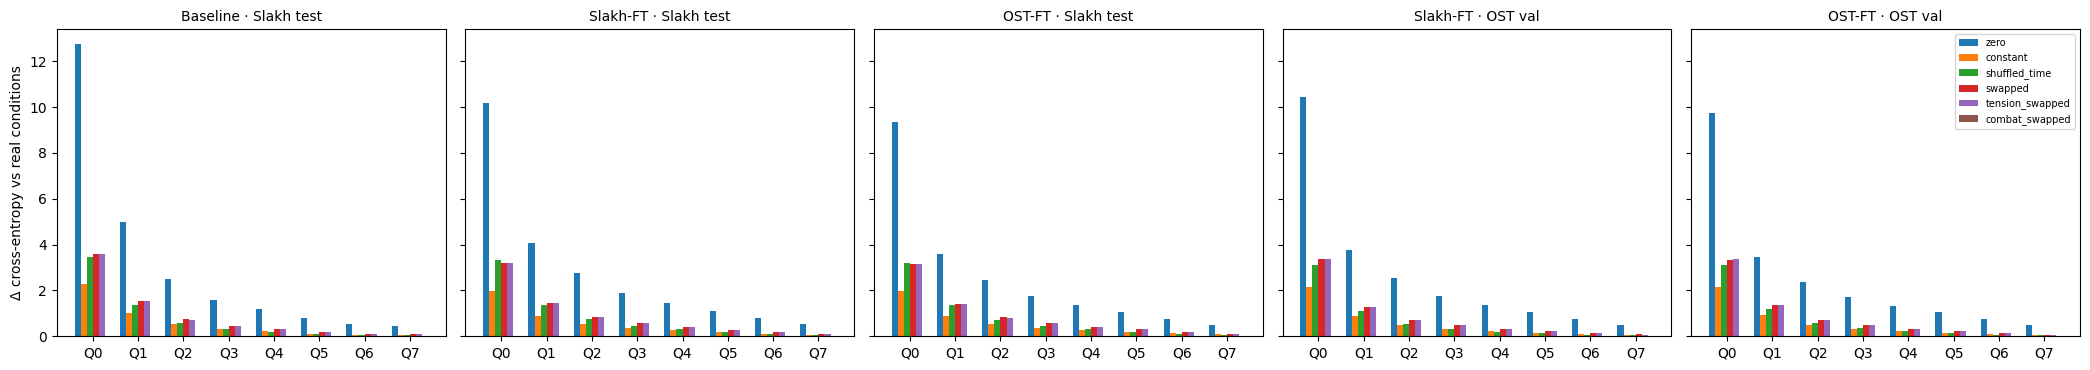

In [7]:
delta_rows = []
for (checkpoint_name, dataset_name, variant), group in segments.groupby(["checkpoint", "dataset", "variant"], sort=False):
    if variant == "real":
        continue
    group = group.set_index(["checkpoint", "dataset", "segment"])
    delta = group[CODEBOOKS] - real.loc[group.index, CODEBOOKS]
    delta_rows.append({"dataset": dataset_name, "checkpoint": checkpoint_name, "variant": variant,
                       **delta.mean().to_dict()})

per_codebook = pd.DataFrame(delta_rows)
per_codebook.to_csv(OUTPUT_DIR / "per_codebook_delta.csv", index=False)
with pd.option_context("display.width", 160):
    print(per_codebook.to_string(index=False, float_format=lambda value: f"{value:+.4f}"))

panels = [(d, c) for d, c in [("Slakh test", "Baseline"), ("Slakh test", "Slakh-FT"), ("Slakh test", "OST-FT"),
                              ("OST val", "Slakh-FT"), ("OST val", "OST-FT")]
          if ((per_codebook["dataset"] == d) & (per_codebook["checkpoint"] == c)).any()]
figure, axes = plt.subplots(1, len(panels), figsize=(4.2 * len(panels), 3.8), sharey=True)
variants = [v for v in ABLATIONS if v != "real"]
x = np.arange(NUM_CODEBOOKS)
width = 0.8 / len(variants)

for axis, (dataset_name, checkpoint_name) in zip(np.atleast_1d(axes), panels):
    subset = per_codebook[(per_codebook["dataset"] == dataset_name) & (per_codebook["checkpoint"] == checkpoint_name)]
    for index, variant in enumerate(variants):
        values = subset[subset["variant"] == variant][CODEBOOKS].to_numpy().ravel()
        axis.bar(x + (index - len(variants) / 2 + 0.5) * width, values, width, label=variant)
    axis.axhline(0, color="black", linewidth=0.6)
    axis.set_xticks(x)
    axis.set_xticklabels(CODEBOOKS)
    axis.set_title(f"{checkpoint_name} · {dataset_name}", fontsize=10)

np.atleast_1d(axes)[0].set_ylabel("Δ cross-entropy vs real conditions")
np.atleast_1d(axes)[-1].legend(fontsize=7)
figure.tight_layout()
figure.savefig(OUTPUT_DIR / "per_codebook_delta.png", dpi=200)
plt.show()

### How to read the result

- `delta_ce` > 0 with a CI that excludes 0, on most segments: the model uses the conditions to predict the real tokens. This is the direct answer to "the metrics would look the same with the conditioning disconnected".
- `delta_ce` ≈ 0: the conditions add no information for predicting the tokens under teacher forcing; the controls would then have to be judged only by E2.
- `tension_swapped` vs `combat_swapped`: which of the two controls the model relies on more.
- `shuffled_time` vs `constant`: whether the model uses the timing of the conditions or mainly their overall level.
- The per-codebook plot shows where the information is used (e.g. coarse codebook Q0 vs fine codebooks).

### Results of this run

**The real conditions reproduce Table 1 exactly** (|diff| = 0 for the three checkpoints), so every variant is compared with the reported evaluation.

**The model uses its conditions.** Replacing them increases the cross-entropy of the real tokens for every checkpoint and on both datasets, with 95% confidence intervals far from zero and on essentially every segment (99–100%):

| Unweighted Δ cross-entropy (Slakh test) | Baseline | Slakh-FT | OST-FT |
|---|---|---|---|
| swapped (other segment's conditions) | +0.87 | +0.88 | +0.87 |
| shuffled_time (right values, wrong timing) | +0.76 | +0.82 | +0.80 |
| constant (median level, no timing) | +0.57 | +0.54 | +0.56 |
| zero | +3.11 | +2.84 | +2.60 |

For scale, Baseline → Slakh-FT improved the same metric by 0.29: wrong conditions cost about three times that improvement. On the OST validation split the effects are of the same size (swapped +0.82 for Slakh-FT, +0.84 for OST-FT). `shuffled_time` is worse than `constant`, so the model uses the timing of the conditions, not only their overall level. `zero` is far worse than the other variants because tension 0 means the minimum signal level: the model is told to expect near-silence.

**Almost all of the effect comes from tension.** `tension_swapped` gives the same increase as `swapped` (+0.87), while `combat_swapped` gives +0.002 (Slakh test) and +0.006 (OST val): statistically above zero but 100–400 times smaller. Under teacher forcing the model barely uses the combat score. A plausible reason is that combat score changes slowly (5-s window, updated once per second) and is largely predictable from the audio already in the context, while tension is frame-level and is computed from the signal level of the very frames being predicted; this explanation is not tested here.

**Where the information is used.** The increase is largest on the coarse codebook Q0 (+3.1 to +3.6 for swapped) and decreases steadily to Q7 (+0.08 to +0.11), consistent with tension describing the overall level of the signal, which the first residual codebooks encode.

**Consequences.** (1) The conditioning pathway is connected and strongly used, so the teacher-forced numbers of Table 1 do depend on the conditions. (2) The combat score is nearly ignored under teacher forcing; experiment E2 must therefore vary tension and combat score independently (in notebook 03 they changed together, so their effects could not be separated) to test whether combat score has any effect at generation time.